In [3]:
import numpy as np
import pandas as pd

In [4]:
df = pd.read_csv('spam.csv')

In [6]:
df.sample(5)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
1863,ham,I'll let you know when it kicks in,NaN,NaN,NaN
4583,ham,Noooooooo please. Last thing I need is stress....,NaN,NaN,NaN
5258,ham,1 in cbe. 2 in chennai.,NaN,NaN,NaN
538,ham,Ummmmmaah Many many happy returns of d day my ...,NaN,NaN,NaN
4783,ham,Indeed and by the way it was either or - not b...,NaN,NaN,NaN


In [7]:
df.shape

(5572, 5)

## 1. Data cleaning

In [8]:
# Data cleaning
# EDA
# text preprocessing
# model building
# evaluation
# improvement
# website
# deploy

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   v1          5572 non-null   str  
 1   v2          5572 non-null   str  
 2   Unnamed: 2  50 non-null     str  
 3   Unnamed: 3  12 non-null     str  
 4   Unnamed: 4  6 non-null      str  
dtypes: str(5)
memory usage: 677.2 KB


In [10]:
# drop last three column
df.drop(columns=['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'],inplace=True)

In [11]:
df.sample(4)

,v1,v2
3516,ham,So you think i should actually talk to him? No...
2140,ham,After the drug she will be able to eat.
5360,ham,"Hey, iouri gave me your number, I'm wylie, rya..."
3029,ham,"Also sir, i sent you an email about how to log..."


In [12]:
# remaining the cols
df.rename(columns={'v1':'target','v2':'text'},inplace=True)

In [13]:
df.sample(4)

,target,text
2023,ham,Is there any movie theatre i can go to and wat...
1468,spam,Hi its LUCY Hubby at meetins all day Fri & I w...
3712,ham,If i not meeting �_ all rite then i'll go home...
2412,spam,I don't know u and u don't know me. Send CHAT ...


In [14]:
from sklearn.preprocessing import LabelEncoder

In [15]:
le =LabelEncoder()

In [16]:
df['target'] = le.fit_transform(df['target'])

In [17]:
df.head()

,target,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [19]:
# missing value
df.isnull().sum()

target    0
text      0
dtype: int64

In [22]:
# check for duplicates values
df.duplicated().sum()

403

In [23]:
# remove duplicates
df = df.drop_duplicates(keep='first')

In [24]:
df.duplicated().sum()

0

In [25]:
df.shape

(5169, 2)

## 2. EDA

In [26]:
df.head()

,target,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [27]:
df.value_counts()

target  text                                                                                                                                                            
0       Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...                                                     1
        Ok lar... Joking wif u oni...                                                                                                                                       1
1       Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's         1
0       U dun say so early hor... U c already then say...                                                                                                                   1
        Nah I don't think he goes to usf, he lives around here though                                                                  

In [29]:
df['target'].value_counts()   # ham =0 , spam =1

target
0    4516
1     653
Name: count, dtype: int64

In [30]:
import matplotlib.pyplot as plt

([<matplotlib.patches.Wedge at 0x1a1b0a8f190>,
 [Text(-1.0144997251399075, 0.4251944351600247, 'ham'),
  Text(1.014499764949479, -0.4251943401757036, 'spam')],
 [Text(-0.5533634864399495, 0.23192423736001344, '87.37'),
  Text(0.5533635081542612, -0.23192418555038377, '12.63')])

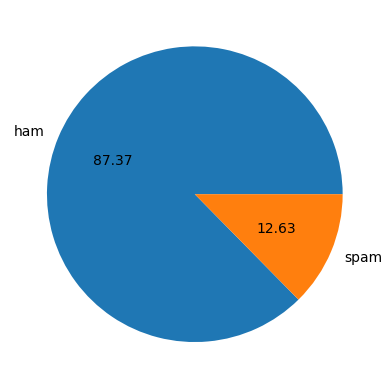

In [34]:
plt.pie(df['target'].value_counts(), labels=['ham','spam'],autopct='%0.2f')

In [35]:
# data is imblanced


In [36]:
import nltk

In [37]:
nltk.download('punkt')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\swati\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [39]:
df['num_characters'] = df['text'].apply(len)

In [40]:
df['num_characters']

0       111
1        29
2       155
3        49
4        61
       ... 
5567    160
5568     37
5569     57
5570    125
5571     26
Name: num_characters, Length: 5169, dtype: int64

In [41]:
df.head()

,target,text,num_characters
0,0,"Go until jurong point, crazy.. Available only ...",111
1,0,Ok lar... Joking wif u oni...,29
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,0,U dun say so early hor... U c already then say...,49
4,0,"Nah I don't think he goes to usf, he lives aro...",61


In [44]:
# num of words
df['num_words'] = df['text'].apply(lambda x:len(nltk.word_tokenize(x)))

In [45]:
df.head()

,target,text,num_characters,num_words
0,0,"Go until jurong point, crazy.. Available only ...",111,24
1,0,Ok lar... Joking wif u oni...,29,8
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37
3,0,U dun say so early hor... U c already then say...,49,13
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15


In [49]:
df['num_sentences'] =  df['text'].apply(lambda x:len(nltk.sent_tokenize(x)))

In [50]:
df.head()

,target,text,num_characters,num_words,num_sentences
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1


In [51]:
df.describe()

,target,num_characters,num_words,num_sentences
count,5169.000000,5169.000000,5169.000000,5169.000000
mean,0.126330,78.924163,18.461405,1.966531
std,0.332253,58.175349,13.335314,1.449833
min,0.000000,2.000000,1.000000,1.000000
25%,0.000000,36.000000,9.000000,1.000000
50%,0.000000,60.000000,15.000000,1.000000
75%,0.000000,117.000000,26.000000,2.000000
max,1.000000,910.000000,220.000000,38.000000


In [53]:
df[['num_characters','num_words','num_sentences']].describe()

,num_characters,num_words,num_sentences
count,5169.000000,5169.000000,5169.000000
mean,78.924163,18.461405,1.966531
std,58.175349,13.335314,1.449833
min,2.000000,1.000000,1.000000
25%,36.000000,9.000000,1.000000
50%,60.000000,15.000000,1.000000
75%,117.000000,26.000000,2.000000
max,910.000000,220.000000,38.000000


In [ ]:
# ham

df[df['target']==0][['num_characters','num_words','num_sentences']].describe()

,num_characters,num_words,num_sentences
count,4516.000000,4516.000000,4516.000000
mean,70.457263,17.128432,1.820195
std,56.357463,13.504730,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [56]:
# spam

df[df['target']==1][['num_characters','num_words','num_sentences']].describe()

,num_characters,num_words,num_sentences
count,653.000000,653.000000,653.000000
mean,137.479326,27.679939,2.978560
std,30.014336,7.014020,1.493185
min,13.000000,2.000000,1.000000
25%,131.000000,25.000000,2.000000
50%,148.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,223.000000,46.000000,9.000000
